In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
from torchvision import datasets , transforms
from torch.utils.data import DataLoader , random_split

import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [2]:
transform = transforms.ToTensor()

train_dataset = datasets.FashionMNIST(root = "data", download = True, train = True, transform = transform)
test_dataset = datasets.FashionMNIST(root = "data", download = True, train = False, transform = transform)

class_names = train_dataset.classes

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))
print("Classes:", class_names)

100%|██████████| 26.4M/26.4M [01:20<00:00, 327kB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 147kB/s]
100%|██████████| 4.42M/4.42M [00:13<00:00, 335kB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 9.97MB/s]

Training samples: 60000
Testing samples: 10000
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [3]:
image , label = train_dataset[0]

print("Image shape:", image.shape)
print("Image dtype:", image.dtype)
print("Label:", label)
print("Class name:", class_names[label])
print("Pixel minimum:", image.min().item())
print("Pixel maximum:", image.max().item())

Image shape: torch.Size([1, 28, 28])
Image dtype: torch.float32
Label: 9
Class name: Ankle boot
Pixel minimum: 0.0
Pixel maximum: 1.0


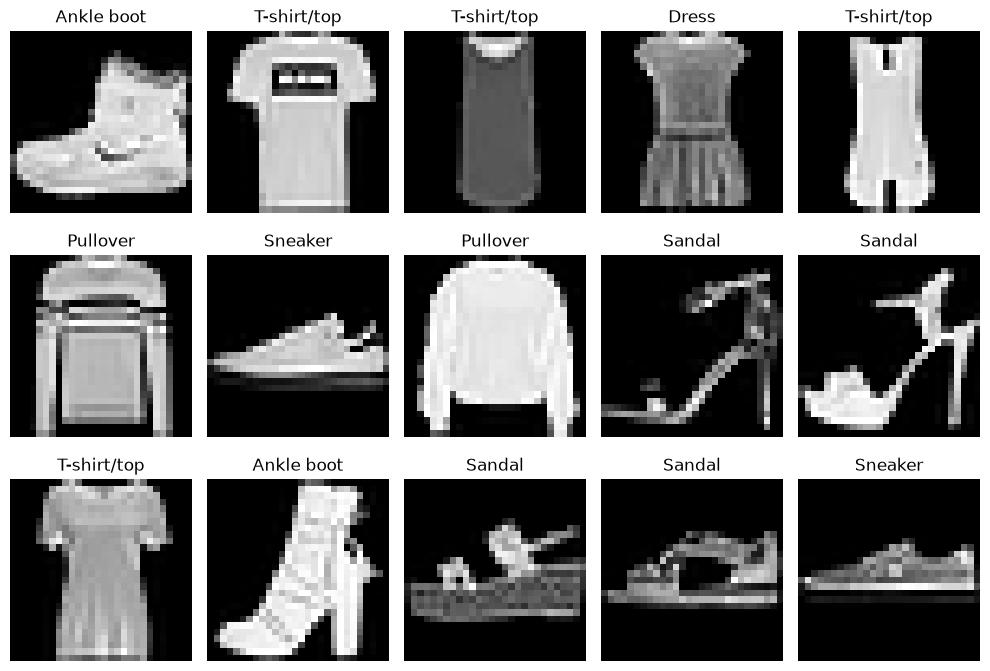

In [6]:
fig , axes = plt.subplots(3,5,figsize = (10,7))

for i,ax in enumerate(axes.flat):
    image , label = train_dataset[i]

    ax.imshow(image.squeeze() , cmap="gray")
    ax.set_title(class_names[label])
    ax.axis(False)

plt.tight_layout()
plt.show()

T-shirt/top: 6000
Trouser: 6000
Pullover: 6000
Dress: 6000
Coat: 6000
Sandal: 6000
Shirt: 6000
Sneaker: 6000
Bag: 6000
Ankle boot: 6000


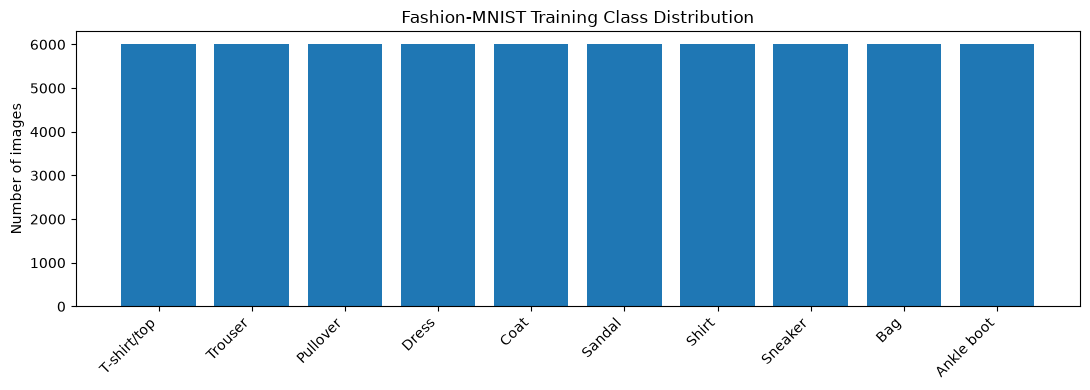

In [7]:
labels = train_dataset.targets.numpy()      #converted labels in numpy matplots lover
unique_classes, counts = np.unique(labels, return_counts=True)      # counted unique elements of each label

for class_name, count in zip(class_names, counts):
    print(f"{class_name}: {count}")

plt.figure(figsize=(11, 4))
plt.bar(class_names, counts)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Number of images")
plt.title("Fashion-MNIST Training Class Distribution")
plt.tight_layout()
plt.show()

In [12]:
BATCH_SIZE = 64

train_dataloader = DataLoader(
    train_dataset,
    batch_size = BATCH_SIZE,
    shuffle = True,
    num_workers = 0
)

test_dataloader = DataLoader(
    test_dataset,
    batch_size = BATCH_SIZE,
    shuffle = False,
    num_workers = 0
)

print("Training batches:", len(train_dataloader))
print("Testing batches:", len(test_dataloader))

# DATALOADER : It divides the dataset into manageable batches.

# shuffle=True randomises the training order each epoch.
# shuffle=False keeps test examples in a consistent order for evaluation.

Training batches: 938
Testing batches: 157


In [15]:
images , label = next(iter(train_dataloader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

# A batch contains 64 images. Each image has one channel and spatial dimensions of 28 × 28. Each label is an integer from 0 to 9.

Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])
Image dtype: torch.float32
Label dtype: torch.int64


In [18]:
class FashionMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10),
        )

    def forward(self, x):
        return self.network(x)

torch.manual_seed(42)
mlp_model = FashionMLP().to("cpu")
print(mlp_model)

FashionMLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [21]:
loss_fn = nn.CrossEntropyLoss()
mlp_optimizer = optim.Adam(params = mlp_model.parameters() , lr = 0.001)

In [30]:
def train_model(model , train_dataloader , optimizer , loss_fn , epochs):
    history = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        correct = 0
        total = 0

        for image,labels in train_dataloader:
            images = image.to("cpu")
            labels = labels.to("cpu")

            logits = model(images)
            loss = loss_fn(logits , labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * image.size(0)
            predictions = logits.argmax(dim = 1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

        epoch_loss = total_loss / total
        epoch_accuracy = correct / total

        history.append({
            "loss": epoch_loss,
            "accuracy": epoch_accuracy
        })

        print(
            f"Epoch [{epoch + 1}/{epochs}] | "
            f"Loss: {epoch_loss:.4f} | "
            f"Accuracy: {epoch_accuracy:.4f}"
        )
    return history

Epoch [1/5] | Loss: 0.5817 | Accuracy: 0.7887
Epoch [2/5] | Loss: 0.3972 | Accuracy: 0.8557
Epoch [3/5] | Loss: 0.3581 | Accuracy: 0.8681
Epoch [4/5] | Loss: 0.3320 | Accuracy: 0.8783
Epoch [5/5] | Loss: 0.3148 | Accuracy: 0.8831


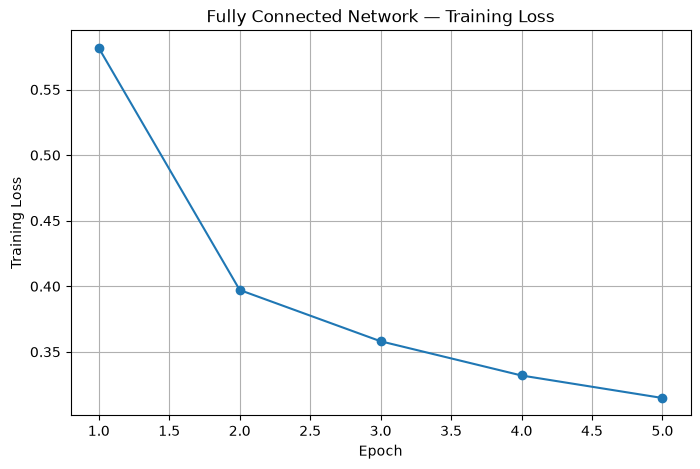

In [31]:
plt.figure(figsize = (8,5))
mlp_history = train_model(
    mlp_model,
    train_dataloader,
    mlp_optimizer,
    loss_fn,
    epochs=5
)

plt.plot(
    range(1, len(mlp_history) + 1),
    [item["loss"] for item in mlp_history],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Fully Connected Network — Training Loss")
plt.grid(True)
plt.show()

In [34]:
def evaluate_model(model , dataloader):
    model.eval()

    all_prediction = []
    all_labels = []
    total_loss = 0
    total = 0

    with torch.no_grad():
        for images , labels in dataloader:
            images = images.to("cpu")
            labels = labels.to("cpu")

            logits = model(images)
            loss = loss_fn(logits , labels)
            predictions = logits.argmax(dim = 1)

            total_loss += loss.item() * images.size(0)
            total += labels.size(0)
            all_prediction.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

        accuracy = np.mean(np.array(all_prediction) == np.array(all_labels))

        return (
            total_loss / total,
            accuracy,
            np.array(all_prediction),
            np.array(all_labels))

mlp_test_loss, mlp_test_accuracy, mlp_predictions, true_labels = (
    evaluate_model(mlp_model, test_dataloader)
)

print(f"MLP test loss: {mlp_test_loss:.4f}")
print(f"MLP test accuracy: {mlp_test_accuracy:.4f}")
print(f"MLP test accuracy (%): {mlp_test_accuracy * 100:.2f}%")

MLP test loss: 0.3551
MLP test accuracy: 0.8733
MLP test accuracy (%): 87.33%


In [37]:
class FashionCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

torch.manual_seed(42)
cnn_model = FashionCNN().to("cpu")
print(cnn_model)

FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [38]:
cnn_optimizer = optim.Adam(params = cnn_model.parameters() , lr = 0.001)

cnn_history = train_model(
    cnn_model,
    train_dataloader,
    cnn_optimizer,
    loss_fn = loss_fn,
    epochs = 5
)

Epoch [1/5] | Loss: 0.5112 | Accuracy: 0.8147
Epoch [2/5] | Loss: 0.3266 | Accuracy: 0.8813
Epoch [3/5] | Loss: 0.2802 | Accuracy: 0.8971
Epoch [4/5] | Loss: 0.2535 | Accuracy: 0.9069
Epoch [5/5] | Loss: 0.2311 | Accuracy: 0.9148


In [ ]:
plt.figure(figsize = (8,5))

plt.plot(range(1,len(mlp_history)+1),
            [item[loss] for item in mlp_history],
            marker = 'o',
            label = "Fully Connected Network")

plt.plot(range(1,len(cnn_history)+1),
            [item[loss] for item in cnn_history],
            marker = 'o',
            label = "CNN")

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("MLP vs CNN — Training Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
cnn_test_loss, cnn_test_accuracy, cnn_predictions, true_labels = (
    evaluate_model(cnn_model,test_dataloader)
)

print("MODEL COMPARISON")
print("-" * 40)

print(f"MLP test loss:      {mlp_test_loss:.4f}")
print(f"MLP test accuracy:  {mlp_test_accuracy * 100:.2f}%")

print(f"\nCNN test loss:      {cnn_test_loss:.4f}")
print(f"CNN test accuracy:  {cnn_test_accuracy * 100:.2f}%")

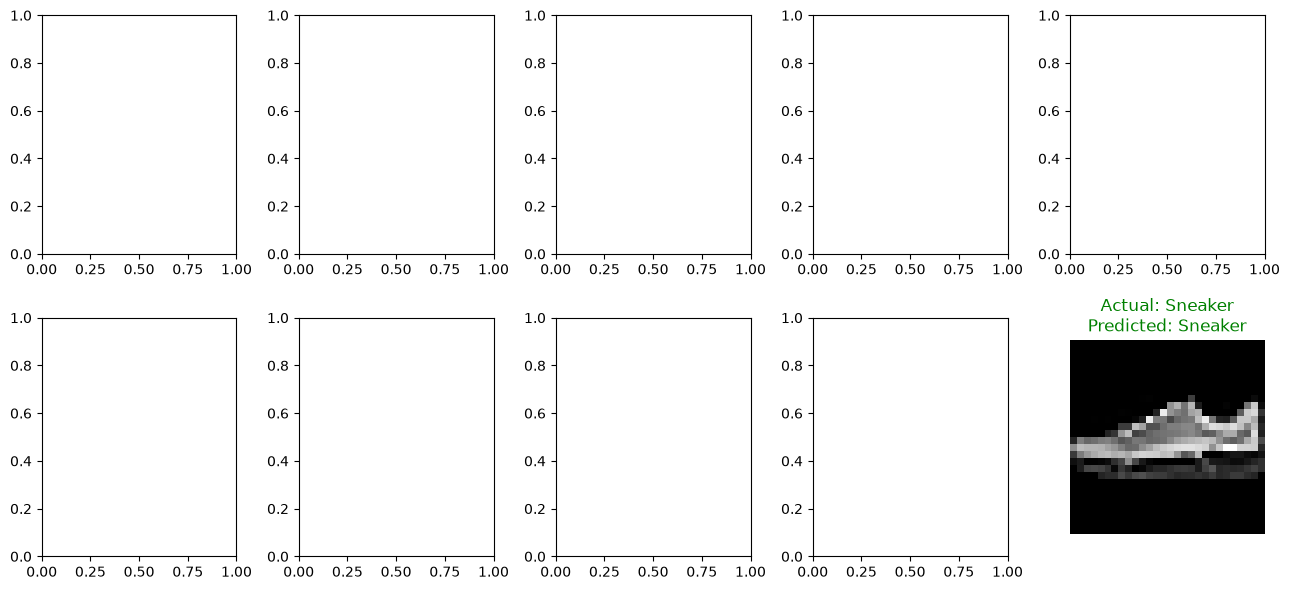

In [48]:
fig,axes = plt.subplots(2,5,figsize=(13,6))

cnn_model.eval()
with torch.no_grad():
    for i,ax in enumerate(axes.flat):
        image,actual_label = test_dataset[i]

        logits = cnn_model(image.unsqueeze(0).to("cpu"))
        predicted_label = logits.argmax(dim=1).item()

    correct = (predicted_label == actual_label)
    correct = (predicted_label == actual_label)
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(
        f"Actual: {class_names[actual_label]}\nPredicted: {class_names[predicted_label]}",
        color="green" if correct else "red"
    )
    ax.axis(False)

plt.tight_layout()
plt.show()


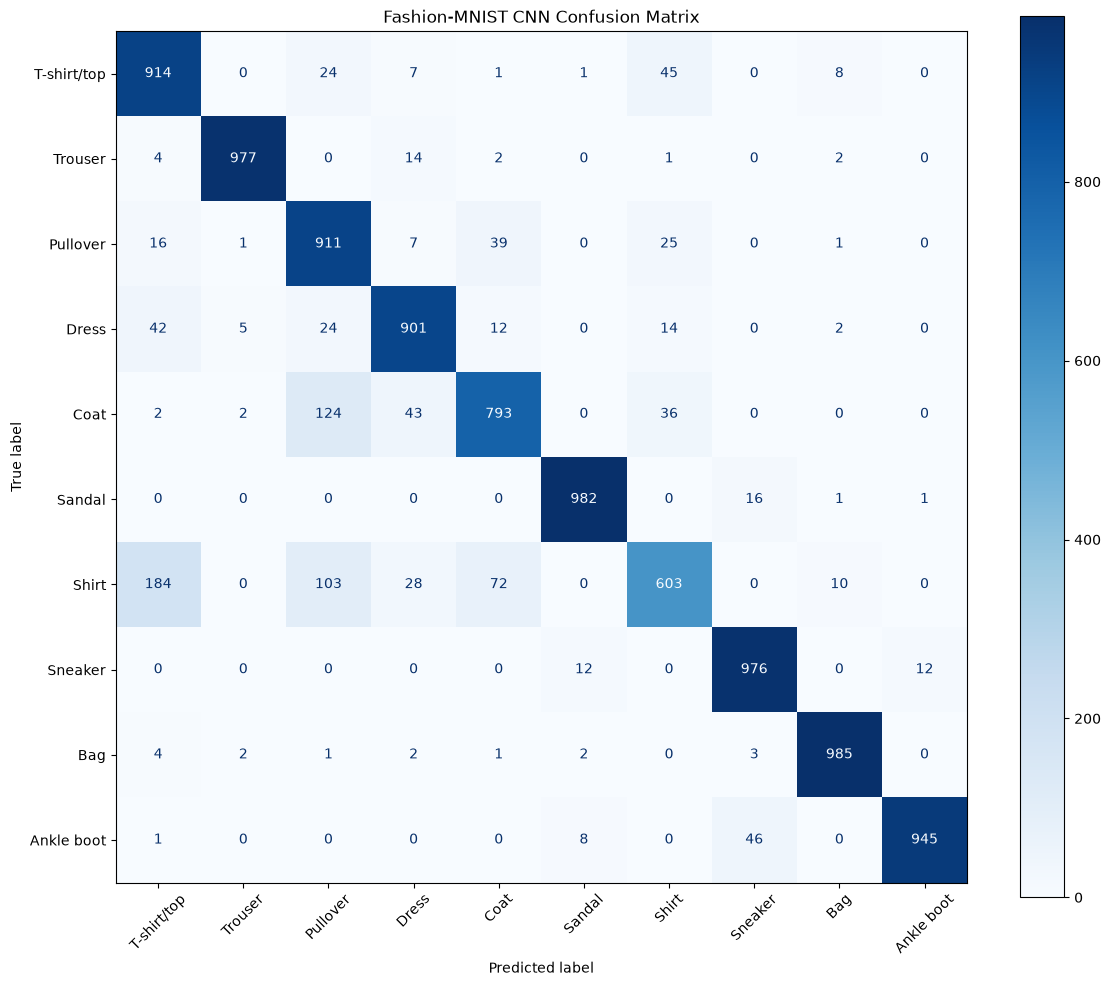

In [58]:
# Recompute the CNN predictions if needed so the confusion matrix always has valid data
cnn_test_loss, cnn_test_accuracy, cnn_predictions, true_labels = evaluate_model(cnn_model, test_dataloader)

cm = confusion_matrix(
    true_labels,
    cnn_predictions,
    labels=list(range(10))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix = cm,
    display_labels = class_names
)

fig,ax = plt.subplots(figsize = (12,10))
disp.plot(ax = ax, values_format = "d", cmap = "Blues", xticks_rotation = 45)
ax.set_title("Fashion-MNIST CNN Confusion Matrix")
plt.tight_layout()
plt.show()

In [57]:
print("True labels:", len(true_labels))
print("CNN predictions:", len(cnn_predictions))
print("Confusion matrix:\n", cm)

True labels: 10000
CNN predictions: 10000
Confusion matrix:
 [[914   0  24   7   1   1  45   0   8   0]
 [  4 977   0  14   2   0   1   0   2   0]
 [ 16   1 911   7  39   0  25   0   1   0]
 [ 42   5  24 901  12   0  14   0   2   0]
 [  2   2 124  43 793   0  36   0   0   0]
 [  0   0   0   0   0 982   0  16   1   1]
 [184   0 103  28  72   0 603   0  10   0]
 [  0   0   0   0   0  12   0 976   0  12]
 [  4   2   1   2   1   2   0   3 985   0]
 [  1   0   0   0   0   8   0  46   0 945]]


In [60]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

print(
    classification_report(
        true_labels,
        cnn_predictions,
        labels = list(range(10)),
        target_names = class_names,
        zero_division = 0
    )
)

              precision    recall  f1-score   support

 T-shirt/top       0.78      0.91      0.84      1000
     Trouser       0.99      0.98      0.98      1000
    Pullover       0.77      0.91      0.83      1000
       Dress       0.90      0.90      0.90      1000
        Coat       0.86      0.79      0.83      1000
      Sandal       0.98      0.98      0.98      1000
       Shirt       0.83      0.60      0.70      1000
     Sneaker       0.94      0.98      0.96      1000
         Bag       0.98      0.98      0.98      1000
  Ankle boot       0.99      0.94      0.97      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000

